<div style="border:4px solid #b00020; background:#ffe5e8; color:#600010; padding:14px 18px; border-radius:6px;">
<h2 style="margin:0 0 8px 0; color:#b00020;">&#9888; WARNING: THE SAMPLE TIME HAS CHANGED</h2>
<p style="margin:4px 0;"><b>The phonon sample period is 0.8 &micro;s (1.25 MHz), not 1.6 &micro;s (625 kHz).</b> A 4096-sample trace is 3.2768 ms. Until 2026-10-22 this notebook used 1.6 &micro;s, which was wrong.</p>
<p style="margin:4px 0;">What this means: times and energies are <b>half</b> of what older versions showed, frequencies are <b>doubled</b>. The time windows in this notebook (in &micro;s or ms) were halved so that they still cover the same samples, so the selection of events and every number counted in samples or counts is unchanged; the absorbed energies are half of what the earlier version printed.</p>
<p style="margin:4px 0;">This notebook was re-run with the new value (the library default, <code>PulseConfig</code> without <code>sample_period_s</code>). See <i>The sample period</i> in <code>python/README.md</code>.</p>
</div>

<div style="border:4px solid #b00020; background:#ffe5e8; color:#600010; padding:14px 18px; border-radius:6px;">
<h2 style="margin:0 0 8px 0; color:#b00020;">&#9888; WARNING: THE CHANNEL MAP HAS CHANGED</h2>
<p style="margin:4px 0;">The dump's twelve board inputs are now mapped for the <b>Side-2 readout</b> of this series (<code>python/pulse_channels.py</code>, pull request 112): <b>six of them are sensors, all on Side 2</b> (DCRC1 pA, pB, pD = Side2pC, Side2pF, Side2pE; DCRC3 pA, pB, pD = Side2pB, Side2pA, Side2pD), DCRC4 pA is the <b>trigger input of the NaI array</b> (not a sensor) and the other five inputs are not connected. The old map used the wrong column of the Setup table. New names of the dump channels: (0, 3) was Side1pF, now Side2pE; (1, 0) was Side1pE, now Side2pB; (1, 1) was Side1pB, now Side2pA; (1, 3) was Side2pE, now Side2pD; (2, 0) was Side2pB, now the NaI input; (0, 0) Side2pC and (0, 1) Side2pF are as before.</p>
<p style="margin:4px 0;"><b>What changed in this notebook:</b> the face is now <b>one face</b> (Side 2) with all six regions active, instead of two faces with seven working channels; the two-face figures, the Side 1 / Side 2 colours and the 'dead' hatching are gone, the frames of the trace panels are coloured by readout board, and every panel title carries the board input. The layout code <code>detector_layout.py</code> was rewritten for one face; the figures were regenerated. <b>The selection is unchanged:</b> the same 48 events, the same three chosen events.</p>
<p style="margin:4px 0;">Everything keyed by <code>(detector, channel)</code> (the cuts, the counts) is unchanged; names, groupings and plots are not. This notebook was re-run with the new map.</p>
</div>

# Small triggers over the detector channel layout, series 07221203_2025, dump 1

The same small real triggers as in `small-physics-triggers-07221203_2025.ipynb`, drawn **on the detector layout** instead of a grid of tiles. Nothing is dropped from the tiled figures: every sensor channel keeps its whole trace (baseline subtracted, grey fit bands, dashed trigger line), all channels of an event share one vertical scale, and each panel carries the channel name, board and rise height.

What the layout adds:

1. **A map in the middle, traces around it.** The face is drawn as in the Note 9 channel figure; each channel's trace is a full-size panel next to its region, joined to it by a leader line. (The thin rings A and B cannot hold a trace, which is why the traces sit in the margin.)
2. **Regions coloured by rise height**, on one colour scale per event, so the pattern of heights across the face is visible at a glance. The readout board (DCRC1 or DCRC3) is the colour of the frames of the trace panels.
3. **One face, six active regions.** The readout of this series is Side 2, so there is one face (flipped as on the wiki, with the x and y arrows) and every one of its six regions has a channel; Side 1 is not read out.
4. **Board and input in every panel title**, for example `Side2pC (DCRC1 pA)`.
5. **A contact sheet** of many events as small maps with the heights printed.
6. **A height-weighted centre** (white star): the mean of the region centres weighted by the rise heights. It is a rough guide to where on the face the event is, not a position reconstruction; the ring channels A and B count as sitting at the centre.

The baseline is a quadratic fitted to the pretrigger samples and to the late tail of the trace, leaving the pulse out (compared with a straight line in section 6 of the first notebook). The helper code is in `small_triggers.py` (the drift-robust rise height and the baseline) and `detector_layout.py` (the drawing), next to this notebook.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().resolve()))      # this notebook's folder, for the two helper modules

import warnings
import numpy as np
import matplotlib.pyplot as plt
from nsdf_dark_matter.idx import load_all_data

import pulse_io as pio
import pulse_cuts as pc
import pulse_channels as pch
from pulse_config import PulseConfig

import check_environment
check_environment.check()

import small_triggers as st
import detector_layout as dl

warnings.filterwarnings("once")
FIGDIR = Path("..") / "figures"      # the figures folder of the R76 notebooks
FIGDIR.mkdir(exist_ok=True)

Environment OK: Python 3.12.15, and the 8 packages in requirements.txt match.


C:\Users\villanoa\Research\NSDF-Data-pn2\data_analysis\R76\notebooks\pulse-normalization\detector_layout.py:28: UserWarning: sensor_channels is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  CHANNELS = {c.letter: c for c in pch.sensor_channels()}      # letter -> Channel record of the six sensors


## 1. Load the dump, the rise heights and the selection

The same steps as in the first notebook: the real triggers (label `Unknown`, the labels are swapped), the drift-robust rise height of every event in every sensor channel, the quiet-pretrigger cut (no pulse, step or strong curvature in the pretrigger window, section 3b of the first notebook) and the provisional small-pulse range `AMP_LOW` to `AMP_HIGH`.

In [2]:
DUMP = "07221203_2025_F0001"          # series 07221203_2025, dump 1
config_500 = PulseConfig(pretrigger_samples=500, glitch_samples=10)
cdms = load_all_data(str(Path.home() / "idx" / DUMP))
det_ids = {det: pio.filter_by_detector(cdms.get_detector_ids(), det) for det in range(3)}
KEYS = [(det, ch) for det in range(3) for ch in range(4)]
ROLE = {(c.detector, c.channel): c.role for c in pch.all_channels()}      # sensor, nai_trigger or not_connected (Side-2 readout)

trigger_types = pio.trigger_types(cdms, det_ids[0])
real = pc.real_triggers(trigger_types)       # label 'Unknown': the pulse triggers (the labels are swapped)
rand = pc.randoms(trigger_types)
event_numbers = np.array([int(pio.event_id(i)) for i in det_ids[0]])

amp, pre_rms, others = {}, {}, []      # others: the inputs that are not sensors (the NaI trigger input, the free inputs)
for key in KEYS:
    if ROLE[key] != pch.SENSOR:
        others.append(key)
        continue
    _, p = pio.load_channel_batch(cdms, det_ids[key[0]], key[1])
    assert p.std(axis=1).max() > 0, f"sensor {pch.channel_name(*key)} never changes"
    amp[key] = st.rise_height(p, config_500)
    pre_rms[key] = st.pretrigger_residual_rms(p, config_500)
working = list(amp)
letter_of = lambda key: pch.channel_info(*key).letter       # the region of the face, 'A' to 'F'
A = np.array([amp[k] for k in working])
amp_max = A.max(axis=0)
max_channel = [working[i] for i in A.argmax(axis=0)]

AMP_LOW, AMP_HIGH = 15.0, 200.0           # counts: provisional range for 'small pulses'
pre_ratio, quiet_pre = st.quiet_pretrigger(pre_rms, rand)      # no pulse, step or strong curvature in the pretrigger window
small = real & quiet_pre & (amp_max >= AMP_LOW) & (amp_max < AMP_HIGH)
print(f"{len(working)} sensor channels; {small.sum()} of {real.sum()} real triggers have a quiet pretrigger and a largest rise height between {AMP_LOW:.0f} and {AMP_HIGH:.0f} counts")

def heights_of(i):
    """letter -> rise height of event i, for the six sensors."""
    return {letter_of(k): float(amp[k][i]) for k in working}

def spread(n):
    """n selected events spread evenly in height through the selection, smallest first."""
    order = np.flatnonzero(small)[np.argsort(amp_max[small])]
    return order[np.linspace(0, len(order) - 1, n + 2).astype(int)[1:-1]]

C:\Users\villanoa\AppData\Local\Temp\ipykernel_14400\724294871.py:6: UserWarning: all_channels is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  ROLE = {(c.detector, c.channel): c.role for c in pch.all_channels()}      # sensor, nai_trigger or not_connected (Side-2 readout)
C:\Users\villanoa\AppData\Local\Temp\ipykernel_14400\724294871.py:9: UserWarning: real_triggers is marked under_development: the other half of the randoms assumption: events recorded as 'Unknown' are taken to be real (pulse-triggered) events. Not confirmed; see `randoms`
  real = pc.real_triggers(trigger_types)       # label 'Unknown': the pulse triggers (the labels are swapped)
C:\Users\villanoa\AppData\Local\Temp\ipykernel_14400\724294871.py:10: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative

6 sensor channels; 48 of 509 real triggers have a quiet pretrigger and a largest rise height between 15 and 200 counts


## 2. One event over the detector layout

For each chosen event: the face with the regions coloured by rise height, and the whole trace of each channel around it, on one vertical scale (set by the largest pulse of the event, in the window from 200 us before to 750 us after the trigger). The scale is shared by all panels of the event, so the channels can be compared by eye; a slow drift far from the pulse can run off the edge. To look at particular events put their numbers in `EVENTS`.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_14400\724294871.py:23: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  letter_of = lambda key: pch.channel_info(*key).letter       # the region of the face, 'A' to 'F'
C:\Users\villanoa\AppData\Local\Temp\ipykernel_14400\362437711.py:23: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  subtitle=f": largest rise height {amp_max[i]:.0f} counts in {pch.channel_name(*max_channel[i])}")
C:\Users\villanoa\Research\NSDF-Data-pn2\python\pulse_channels.py:129: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC

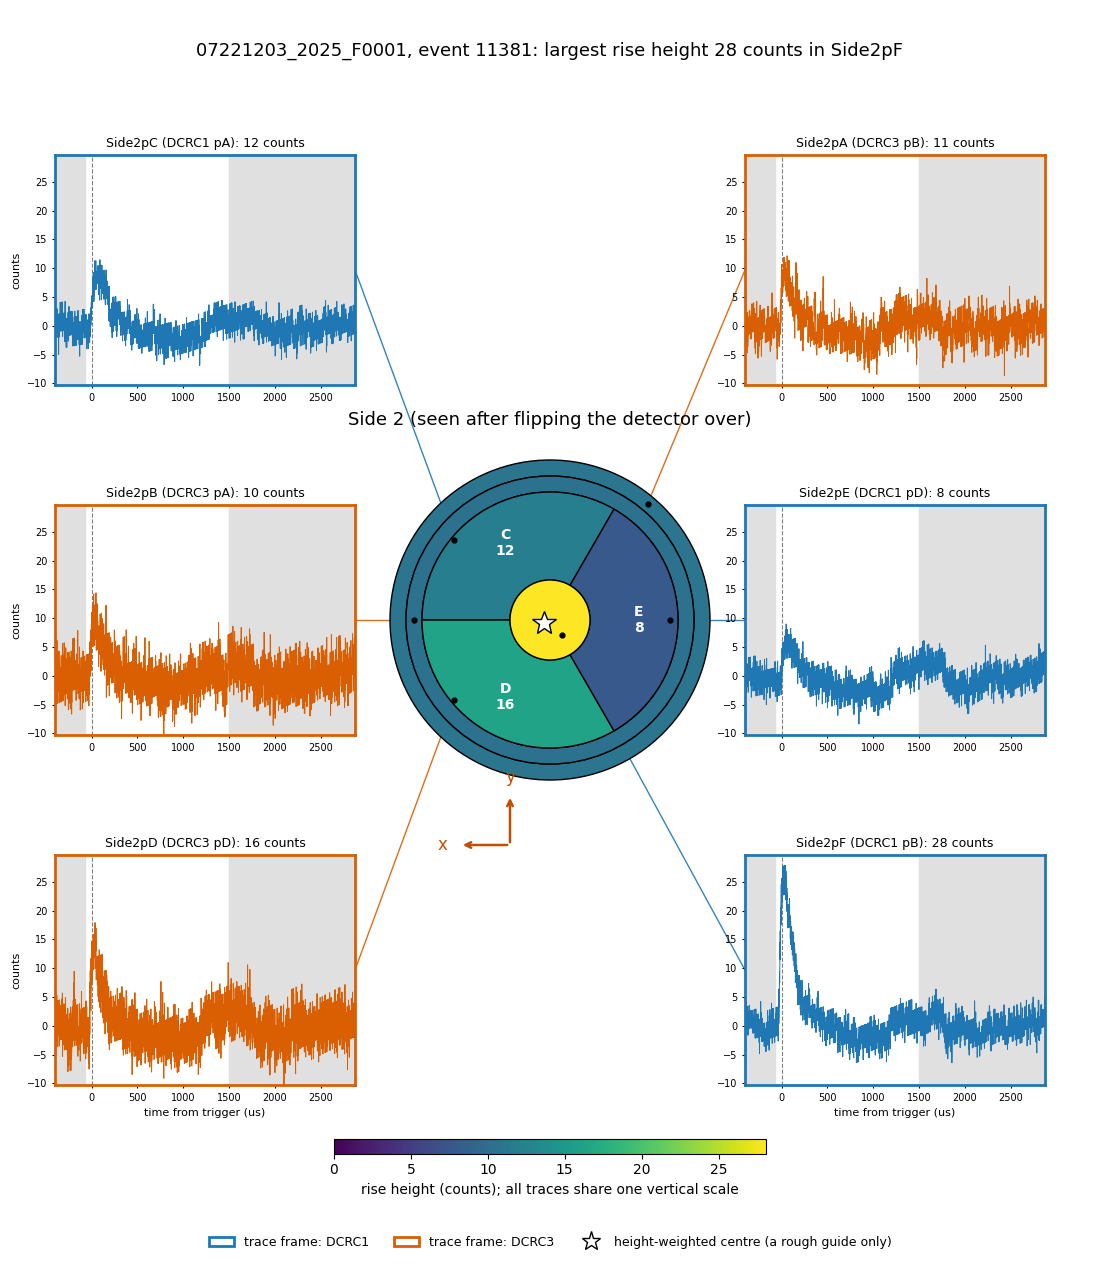

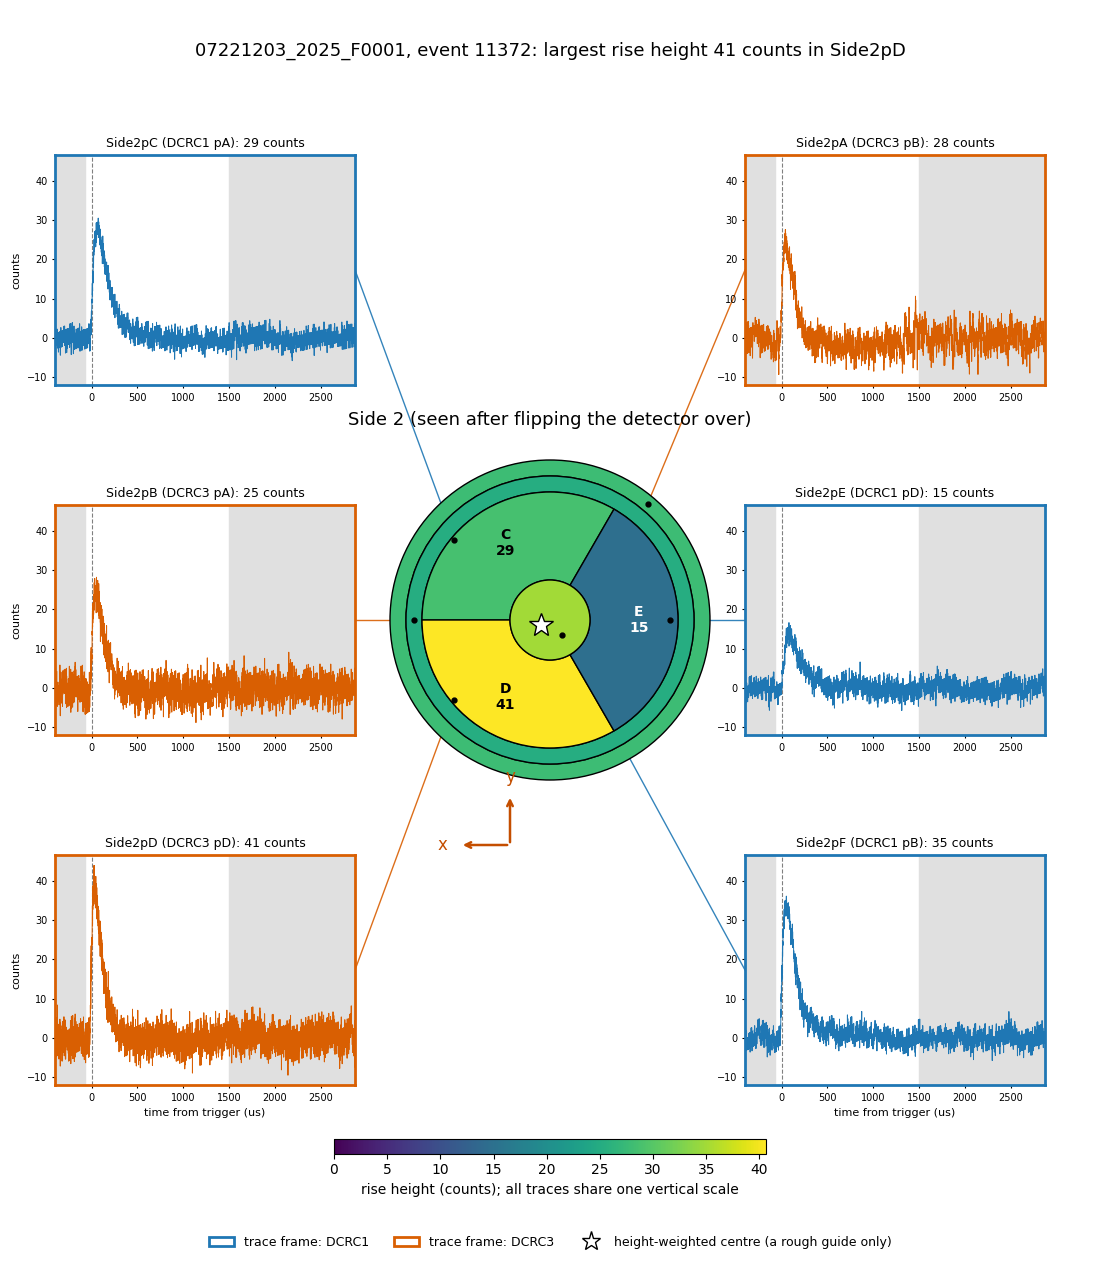

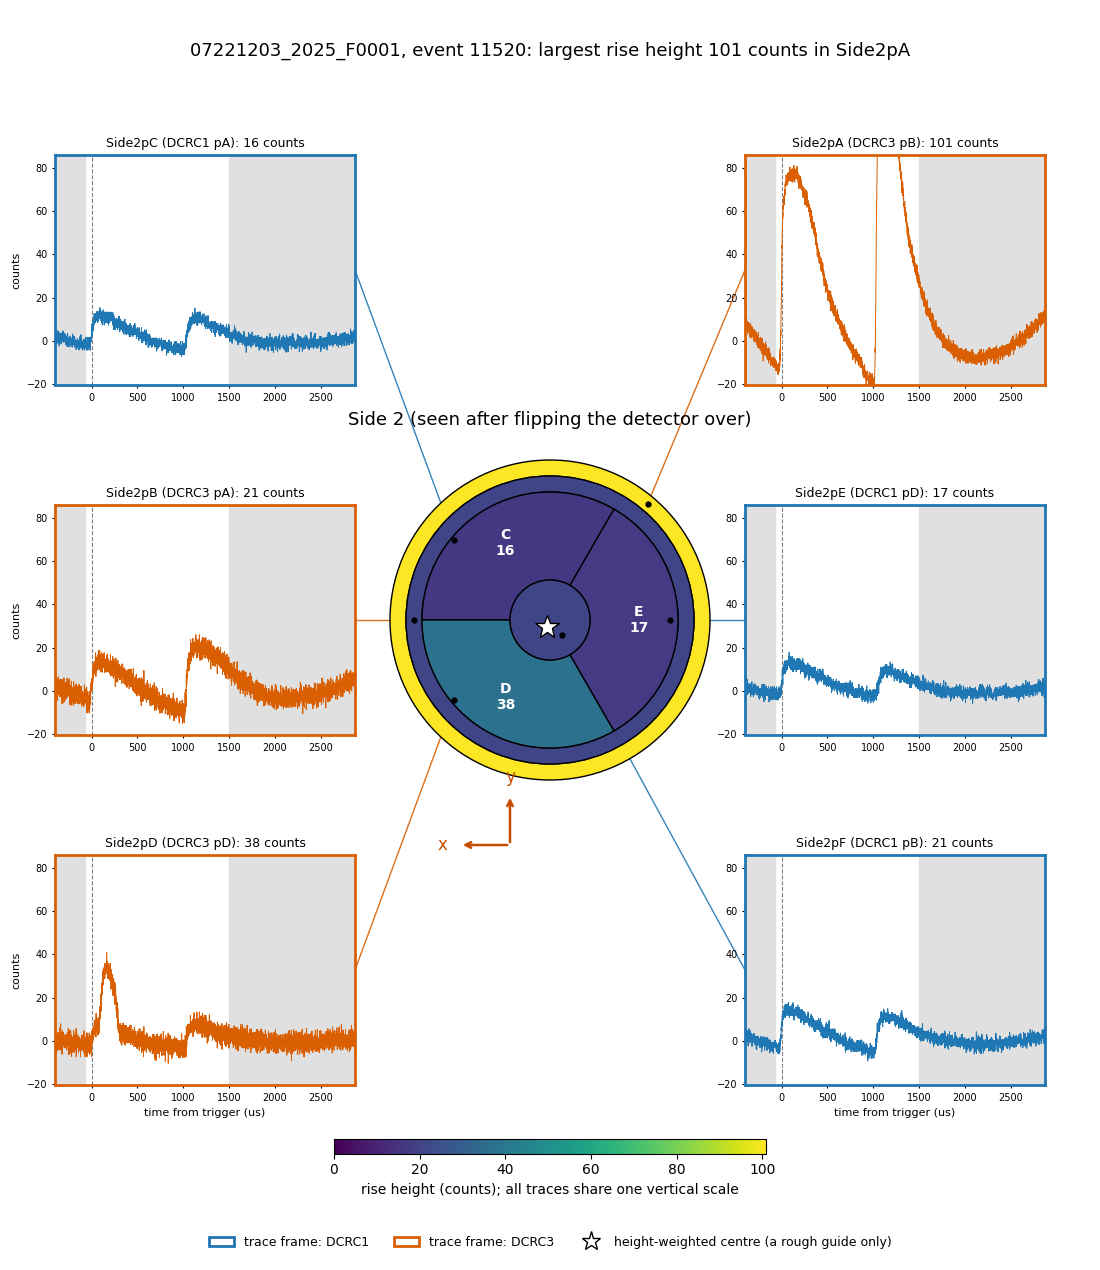

In [3]:
N_EVENTS = 3
EVENTS = None                      # or a list of event numbers, e.g. [11095, 11221]
chosen = spread(N_EVENTS) if EVENTS is None else np.array([np.flatnonzero(event_numbers == ev)[0] for ev in EVENTS])

chosen_traces = {}
for key in working:
    _, p = pio.load_channel_batch(cdms, det_ids[key[0]], key[1])
    chosen_traces[key] = p[chosen]
n_samples = chosen_traces[working[0]].shape[-1]
t_us = (np.arange(n_samples) - config_500.pretrigger_samples) * config_500.sample_period_s * 1e6
t_fit = [((config_500.glitch_samples - config_500.pretrigger_samples) * config_500.sample_period_s * 1e6,
          (st.fit_end(config_500) - config_500.pretrigger_samples) * config_500.sample_period_s * 1e6),
         (st.TAIL_FROM_US, t_us[-1])]          # where the baseline is fitted: before the pulse and in the late tail
near_pulse = (t_us >= -200) & (t_us <= 750)

for n, i in enumerate(chosen):
    flats = {letter_of(k): st.subtract_baseline(chosen_traces[k][n][None, :], config_500)[0] for k in working}
    lo = min(f[near_pulse].min() for f in flats.values())
    hi = max(f[near_pulse].max() for f in flats.values())
    pad = 0.05 * (hi - lo)
    h = heights_of(i)
    fig = dl.draw_event_layout(f"{DUMP}, event {event_numbers[i]}", t_us, flats, h, t_fit, (lo - pad, hi + pad),
                               subtitle=f": largest rise height {amp_max[i]:.0f} counts in {pch.channel_name(*max_channel[i])}")
    fig.savefig(FIGDIR / f"layout-event{event_numbers[i]}-{DUMP}.png", dpi=110)
    plt.show()

## 3. Contact sheet of many events

Small maps of selected events, spread evenly in height through the selection (smallest first). Each map is coloured on its own scale, from zero to the largest height of that event, which is printed with its channel; the heights of the three large regions are printed in them (and those of the rings and the disc below the map). The white star is the height-weighted centre.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_14400\724294871.py:23: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  letter_of = lambda key: pch.channel_info(*key).letter       # the region of the face, 'A' to 'F'
C:\Users\villanoa\AppData\Local\Temp\ipykernel_14400\1579460047.py:4: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  top=f"largest {amp_max[i]:.0f} counts, in {pch.channel_name(*max_channel[i])}") for i in sheet]


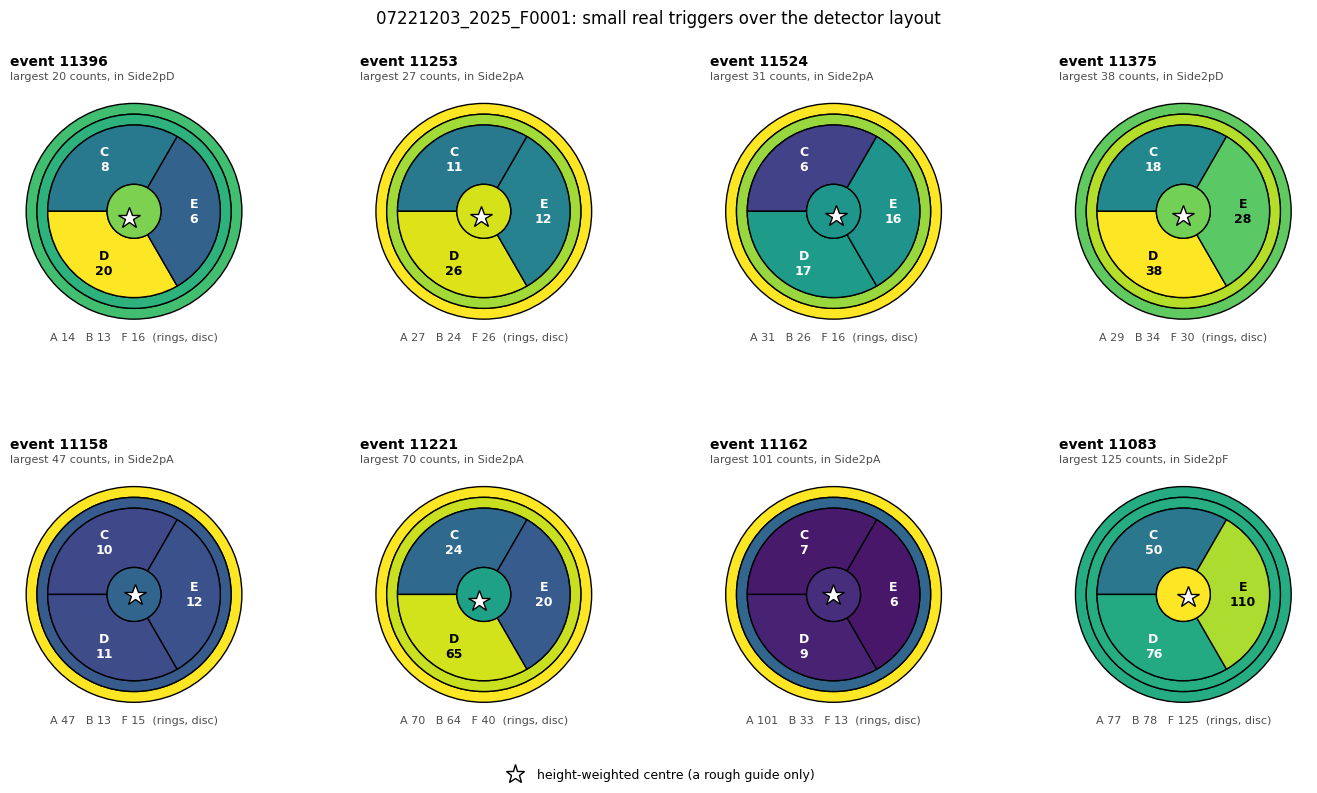

In [4]:
N_SHEET = 8
sheet = spread(N_SHEET)
events = [dict(label=f"event {event_numbers[i]}", heights=heights_of(i),
               top=f"largest {amp_max[i]:.0f} counts, in {pch.channel_name(*max_channel[i])}") for i in sheet]
fig = dl.draw_contact_sheet(events, title=f"{DUMP}: small real triggers over the detector layout")
fig.savefig(FIGDIR / f"layout-contact-sheet-{DUMP}.png", dpi=110, bbox_inches="tight")
plt.show()